<a href="https://colab.research.google.com/github/KillianSambourg/TP_DICOM/blob/main/DICOM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DQPRM

## Manipuler des images au format DICOM à l'aide des bibliothèques SimpleITK et pydicom

#### Albertine Dubois - albertine.dubois@cea.fr & Ludovic Ferer - Ludovic.Ferrer@ico.unicancer.fr

Version d'octobre 2024

---

## Structure d'un fichier DICOM

L'extension `.dcm` désigne un fichier DICOM.

Dans un fichier DICOM, les données sont organisées de façon séquentielle en commencant par une **entête** (1%), suivie des **données brutes** de l'image (99%).

<center>
<img width=500 src="./data/dicom2.png">
</center>

L'entête DICOM ou *DICOM Tag Header* contient un ensemble d'informations spécifiques appelées **meta-données**, renseignées par des attributs aussi appelés étiquettes ou *tags* en anglais.

* Attributs constructeur
* Attributs patient (état civil, âge, poids etc.)
* Attributs examen (région explorée, technique d'imagerie utilisée, date d'acquisition, praticien etc.)

Lire l'entête DICOM peut s'avérer utile pour :
* Contrôler l'origine d'une image
* Vérifier des paramètres d'acquisition (traceur, kV, champ magnétique)
* Extraire des données pour la recherche (traitement d'images)

Les données brutes de l'image peuvent être :
* Non comprimées (RAW)
* ...ou comprimées (24 types différents)
    * RLE
    * JPEG Lossless (1:2 sans perte)
    * JPEG lossy (1:20 avec perte)
    * JPEG2000...

A l'issue d'un examen médical, un dossier parfois nommé *DICOMDIR* contient la liste des fichiers générés (images, compressées ou non, parfois des vidéos voire des compte-rendus). Il est possible de visualiser la totalité d'un examen dans l'ordre chronologique et par série (par exemple, coupes avant injection, coupes après injection, reconstruction selon un autre plan de coupe etc.).

<center>
<img width=600 src="./data/dicomstructure.jpg">
</center>
    
Les particularités des fichiers DICOM ainsi que les besoins spécifiques des médecins qui les utilisent justifient l'existence de logiciels dédiés pour les manipuler mais aussi pour les classer et pour les partager en réseau (PACS - Picture Archiving and Communication Systems).

Les consoles d'acquisition et de nombreux logiciels libres de visualisation et de traitement d'images permettent aujourd'hui la lecture des entêtes et des images DICOM. Le site de la NEMA en propose une large sélection, régulièrement mise à jour (http://idoimaging.com/programs).

## Préambule

Il peut être parfois utile de commencer par créer une cellule permettant de définir l'environnement de travail nécessaire à l'exécution du notebook : import des bibliothèques et des fonctions utiles, définition des répertoires (répertoire courant, données d'entrée et de sortie) etc.

In [ ]:
# Import des librairies de base
import numpy as np
import matplotlib.pyplot as plt
import os

# Import de la librairie SimpleITK
import SimpleITK as sitk

# Import some interactive IPython widgets
# The interact function (ipywidgets.interact) automatically creates user interface (UI) controls for exploring code and data interactively.
from ipywidgets import interact, interactive, fixed

# Definition du répertoire de travail courant
PWD_DIR = os.getcwd()

# Definition du répertoire dans lequel on stockera les données de sortie
OUTPUT_DIR = os.path.join(PWD_DIR,'output')
# S'il n'existe pas, on le crée
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)

ModuleNotFoundError: No module named 'SimpleITK'

## Première méthode pour charger des séries d'images DICOM

Dans les cellules suivantes, nous allons procéder à la **lecture** de séries d'images DICOM obtenues après une acquisition TEP/TDM, à leur **affichage** et à leur **sauvegarde** sous la forme de fichiers image 3D au format mhd/mha ou nii. Dans notre exemple, les deux séries d'images sont stockées dans un seul et même répertoire (mais ce n'est pas toujours le cas).

### 1. Lecture des séries d'images DICOM TEP et TDM

#### 1.1 Identification des numéros de séries corresondant aux données TEP et TDM

In [ ]:
# Define DICOM data directory
data_dcm_directory = './data/patient2/'
print("Path to DICOM data directory:",data_dcm_directory)

# Provide a file name that belongs to the DICOM CT series you want to read
#!ls './data/patient2/'
file_name_ct= os.path.join(data_dcm_directory,'Patient2.CT._.4.1.2019.11.21.11.52.34.596.71223801.dcm')

# Read the file's meta-information without reading bulk pixel data
file_reader_ct=sitk.ImageFileReader()
file_reader_ct.SetFileName(file_name_ct)
file_reader_ct.ReadImageInformation()

# Get the sorted file names, open all files in the directory and read the meta-information without reading the bulk pixel data
series_ID_ct=file_reader_ct.GetMetaData('0020|000e')
sorted_file_names_ct=sitk.ImageSeriesReader.GetGDCMSeriesFileNames(data_dcm_directory,series_ID_ct)
print("Series ID corresponding to CT data:",series_ID_ct)

# Provide a file name that belongs to the DICOM PET series you want to read
file_name_pet=os.path.join(data_dcm_directory,'Patient2.PT._.3.144.2019.11.21.11.52.34.596.71220765.dcm')
# Read the file's meta-information without reading bulk pixel data
file_reader_pet=sitk.ImageFileReader()
file_reader_pet.SetFileName(file_name_pet)
file_reader_pet.ReadImageInformation()

# Get the sorted file names, open all files in the directory and read the meta-information without reading the bulk pixel data
series_ID_pet=file_reader_pet.GetMetaData('0020|000e')
sorted_file_names_pet=sitk.ImageSeriesReader.GetGDCMSeriesFileNames(data_dcm_directory,series_ID_pet)
print("Series ID corresponding to PET data:",series_ID_pet)

Path to DICOM data directory: ./data/patient2/


NameError: name 'sitk' is not defined

#### 1.2 Lecture des images et de leurs attributs

In [ ]:
# Read DICOM CT and PET images and convert them to NumPy arrays
# Access to their attributes (size, origin and spacing)
img_ct=sitk.ReadImage(sorted_file_names_ct)
print('Image CT size: ', img_ct.GetSize())
print('Image CT origin: ', img_ct.GetOrigin())
print('Image CT spacing: ', img_ct.GetSpacing(),'\n')

img_pet=sitk.ReadImage(sorted_file_names_pet)
print('Image PET size: ', img_pet.GetSize())
print('Image PET origin: ', img_pet.GetOrigin())
print('Image PET spacing: ', img_pet.GetSpacing())

### 2. Affichage des images DICOM

#### 2.1 Utilisation de Matplotlib et de la fonction interact

Comme dans le notebook précédent, on va d'abord convertir les images qui sont toujours des objets SimpleITK en arrays NumPy.

In [ ]:
nimg_ct = sitk.GetArrayFromImage(img_ct)
print(nimg_ct.shape)
nimg_pet = sitk.GetArrayFromImage(img_pet)
print(nimg_pet.shape)

(568, 512, 512)
(419, 200, 200)


Ci-dessous, on crée une fonction permettant l'affichage d'une image 3D selon ses 3 plans de coupe

In [ ]:
# Home-made function to show a 3D image in three views
def show_image(arr,sx,sy,sz,color):
    fig, ax = plt.subplots(1,3, figsize=(10, 10))
    ax[0].imshow(arr[sz,:,:], cmap=str(color)) #
    ax[0].set_title("Vue axiale (transverse)")
    ax[1].imshow(arr[:,sy,:], cmap=str(color), origin='lower')
    ax[1].set_title("Vue coronale (frontale)")
    ax[2].imshow(arr[:,:,sx], cmap=str(color), origin='lower')
    ax[2].set_title("Vue sagittale")

In [ ]:
# View CT
interact(show_image, arr=fixed(nimg_ct), sx=(0,img_ct.GetSize()[0]-1), sy=(0,img_ct.GetSize()[1]-1), sz=(0,img_ct.GetSize()[2]-1),color='gray');

interactive(children=(IntSlider(value=255, description='sx', max=511), IntSlider(value=255, description='sy', …

In [ ]:
# View PET
interact(show_image, arr=fixed(nimg_pet), sx=(0,img_pet.GetSize()[0]-1), sy=(0,img_pet.GetSize()[1]-1), sz=(0,img_pet.GetSize()[2]-1),color='jet');

interactive(children=(IntSlider(value=99, description='sx', max=199), IntSlider(value=99, description='sy', ma…

Comme vous pouvez le constater, l'utilisation de la fonction `imshow` de Matplotlib (très efficace par ailleurs) devient problématique dès lors qu'on travaille avec des images qui ont une haute dynamique ou qui ont un voxel size non isotrope, ce qui est le cas de la plupart des images médicales 3D. L'image apparait ainsi déformée à l'affichage.

Quand on travaille avec des images médicales, il est recommandé de les visualiser à l'aide de logiciels dédiés comme par exemple [3D Slicer](https://www.slicer.org/) ou [ITK-SNAP](http://www.itksnap.org/pmwiki/pmwiki.php), tous deux téléchargeables gratuitement.

### 2.2 Sauvegarder les series d'images DICOM en images directement 3D

In [ ]:
# Read the bulk pixel data and write them as a single 3D nii or mha file
output_file_name_3D_ct = os.path.join(OUTPUT_DIR, '3DImageCT.nii') #'3DImageCT.mha'
sitk.WriteImage(img_ct, output_file_name_3D_ct)
output_file_name_3D_pet = os.path.join(OUTPUT_DIR, '3DImagePET.nii') #'3DImagePET.mha'
sitk.WriteImage(img_pet, output_file_name_3D_pet)

## Deuxième méthode pour charger des séries d'images DICOM

Dans les cellules suivantes, vous allez découvrir comment avec **une seule boucle**, on peut **lire**, **afficher** et **sauvegarder** des séries d'images DICOM (à réutiliser sans modération)

In [ ]:
data_dcm_directory = './data/patient2/'
print("Path to DICOM data directory:",data_dcm_directory)

# Directory contains multiple DICOM studies/series, store in dictionary with key being the series ID
reader = sitk.ImageSeriesReader()
series_file_names = {}
series_IDs = reader.GetGDCMSeriesIDs(data_dcm_directory)

Path to DICOM data directory: ./data/patient2/


Il y a 2 serie(s) dans le dossier ./data/patient2/

Serie numéro 1
Series ID: 1.3.12.2.1107.5.8.15.101920.30000019112111472618900004656
Modality: PT
-> Sauvegarde de l'image PT.nii -> OK

Serie numéro 2
Series ID: 1.3.12.2.1107.5.8.15.101920.30000019112111472618900005078
Modality: CT
-> Sauvegarde de l'image CT.nii -> OK



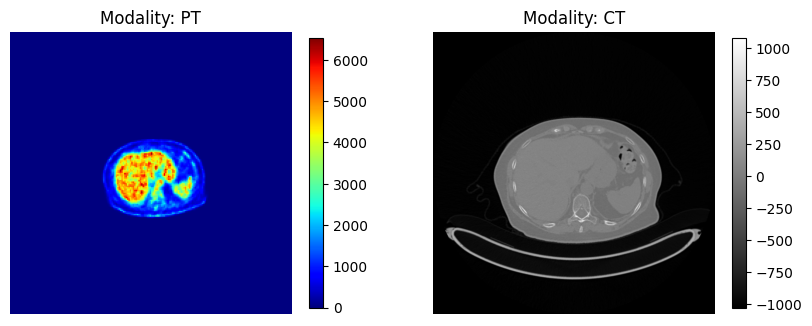

In [ ]:
# Display both modality imaging side by side
plt.subplots(1,2,figsize=(10,5))
# Check that we have at least one series
if series_IDs:
    print("Il y a " + str(len(series_IDs)) + " serie(s) dans le dossier " + data_dcm_directory+'\n')
    for i, series in enumerate(series_IDs):
        print("Serie numéro", i+1)
        print('Series ID:', series)
        series_file_names[series] = reader.GetGDCMSeriesFileNames(data_dcm_directory, series)
        reader.SetFileNames(series_file_names[series])
        reader.MetaDataDictionaryArrayUpdateOn()
        reader.LoadPrivateTagsOn()
        img = reader.Execute()
        modality=reader.GetMetaData(2,'0008|0060')
        print('Modality:',modality)
        sitk.WriteImage(img,os.path.join(OUTPUT_DIR,str(modality)+".nii"))
        print("-> Sauvegarde de l'image "+str(modality)+".nii "+"-> OK\n")
        # Display the image slice from the middle of the stack, z axis
        z = int(img.GetDepth()/2)
        plt.subplot(1,2,i+1)
        if modality == 'CT':
            plt.imshow(sitk.GetArrayViewFromImage(img)[z,:,:], cmap='gray')
        if modality == 'PT':
            plt.imshow(sitk.GetArrayViewFromImage(img)[z,:,:], cmap='jet')
        plt.title('Modality: ' + modality)
        plt.axis('off')
        plt.colorbar(shrink=0.7)
else:
    print('Data directory does not contain any DICOM series.')

In [ ]:
## La librairie pydicom

La librairie [pydicom](https://pydicom.github.io/) offre de nombreuses fonctionnalités pour manipuler assez simplement des fichiers DICOM en Python, en particulier leurs meta-données.

Dans le notebook précédent, nous avons ouvert et analysé le fichier image intitulé `PosteriorStatic001_DS.dcm`. L'extension de ce fichier nous indique qu'il s'agit d'une image DICOM et son nom qu'il s'agit certainement d'une image de scintigraphie. Nous allons vérifier cela et plus généralement nous intéresser aux meta-données de cette image en l'ouvrant cette fois-ci non plus avec `SimpleITK` mais avec avec le module `pydicom`.

Importez le module `pydicom` pour pouvoir l'utiliser dans votre programme.

In [ ]:
import pydicom as dcm

La commande suivante execute la fonction `read_file` du module pydicom qu'on a renommé dcm.

In [ ]:
dataset = dcm.dcmread('./data/PosteriorStatic001_DS.dcm')

En tapant `dataset`, on affiche l'ensemble des meta-données du fichier DICOM.

In [ ]:
dataset

Dataset.file_meta -------------------------------
(0002,0000) File Meta Information Group Length  UL: 212
(0002,0001) File Meta Information Version       OB: b'\x00\x01'
(0002,0002) Media Storage SOP Class UID         UI: Nuclear Medicine Image Storage
(0002,0003) Media Storage SOP Instance UID      UI: 1.2.840.113619.2.184.21753.172177051.1554192655.109687500
(0002,0010) Transfer Syntax UID                 UI: Explicit VR Little Endian
(0002,0012) Implementation Class UID            UI: 1.2.840.113619.6.184
(0002,0013) Implementation Version Name         SH: 'Xeleris 2.1753'
(0002,0016) Source Application Entity Title     AE: 'XELERIS-MED'
-------------------------------------------------
(0008,0000) Group Length                        UL: 528
(0008,0008) Image Type                          CS: ['DERIVED', 'PRIMARY', 'STATIC', 'EMISSION']
(0008,0012) Instance Creation Date              DA: '20190402'
(0008,0013) Instance Creation Time              TM: '101108.0000'
(0008,0014) Instanc

* Les meta-données sont organisées en plusieurs **groupes d'informations**
* Chaque groupe d'informations contient plusieurs **éléments** ou **attributs**

L'ensemble de ces meta-données constitue un dictionnaire de données DICOM.

<center>
<img src="./data/dicomstructure.png">
</center>


Choisissons un attribut particulier

In [ ]:
dataset[0x008,0x060]

(0008,0060) Modality                            CS: 'NM'

La commande précédente affiche la ligne correspondant à l'élément ou attribut ou *tag element* (0008, 0060).

Le format de cette ligne est le suivant :

- **(0008, 0060)** : numéro de l'attribut (*tag number*), codé en hexadecimal suivant (numéro du groupe, numéro de l'attribut)

- **Modality** : nom de cet attribut, s'il est connu

- **CS**: valeur de représentation de l'attribut, si elle est connue

- **'NM'**: valeur de l'attribut considéré


Pour accéder à un attribut spécifique, on peut utiliser son numéro (dans l'exemple ci-dessus, c'est (0x008,0x060)) ou le mot-clé DICOM correspondant (dans l'exemple ci-dessus, c'est `Modality`).

Le mot-clé est généralement le même que le nom de l'élément sans espace. Quelques exceptions néanmoins comme `(0010,0010) Patient’s Name` dont le mot-clé correspondant est `PatientName`.

Une liste de tous les mots-clé peut être consultée [ici](http://dicom.nema.org/medical/dicom/current/output/chtml/part06/chapter_6.html).

In [ ]:
dataset['Modality']

(0008,0060) Modality                            CS: 'NM'

In [ ]:
dataset[0x008,0x080].value

'CHU Hautepierre'

In [ ]:
dataset['Modality'].value

'NM'

In [ ]:
dataset.Modality

'NM'

In [ ]:
print("Patient's Name:", dataset.PatientName)
print('Patient ID:', dataset[0x0010,0x0020].value)

Patient's Name: DMSA^ENFANT^^^
Patient ID: 2260430


La commande suivante permet de trier le dataset, en affichant uniquement l'ensemble des éléments du groupe d'informations `0010`

In [ ]:
dataset.group_dataset(0x0010)

(0010,0000) Group Length                        UL: 116
(0010,0010) Patient's Name                      PN: 'DMSA^ENFANT^^^'
(0010,0020) Patient ID                          LO: '2260430'
(0010,0030) Patient's Birth Date                DA: '20160404'
(0010,0040) Patient's Sex                       CS: 'F'
(0010,1000) Other Patient IDs                   LO: ''
(0010,1001) Other Patient Names                 PN: ''
(0010,1020) Patient's Size                      DS: '0'
(0010,1030) Patient's Weight                    DS: '16'
(0010,2160) Ethnic Group                        SH: ''
(0010,2180) Occupation                          SH: ''

La commande suivante permet d'afficher la valeur du tag number associé à l'attribut `Patient ID`.

In [ ]:
print(dataset.data_element("PatientID").tag)

(0010,0020)


Vérifions

In [ ]:
print(dataset[0x0010,0x0020].value)

2260430


La fonction `dataset.dir()` permet de retrouver tous les mots-clés contenant une chaîne de caractère donnée.

In [ ]:
dataset.dir('patien')

['OtherPatientIDs',
 'OtherPatientNames',
 'PatientBirthDate',
 'PatientGantryRelationshipCodeSequence',
 'PatientID',
 'PatientName',
 'PatientOrientationCodeSequence',
 'PatientPosition',
 'PatientSex',
 'PatientSize',
 'PatientWeight']

In [ ]:
liste = dataset.dir('patien')

In [ ]:
print(liste)

['OtherPatientIDs', 'OtherPatientNames', 'PatientBirthDate', 'PatientGantryRelationshipCodeSequence', 'PatientID', 'PatientName', 'PatientOrientationCodeSequence', 'PatientPosition', 'PatientSex', 'PatientSize', 'PatientWeight']


In [ ]:
for i in liste:
#    print(i)
    print(i,"=>",dataset[i].value)

OtherPatientIDs => 
OtherPatientNames => 
PatientBirthDate => 20160404
PatientGantryRelationshipCodeSequence => []
PatientID => 2260430
PatientName => DMSA^ENFANT^^^
PatientOrientationCodeSequence => []
PatientPosition => 
PatientSex => F
PatientSize => 0
PatientWeight => 16


## Utilisation de pydicom conjointement avec Matplotlib

L'utilisation de la bibliothèque pydicom est principalement dédiée à l'exploration et la manipulation des meta-données DICOM.

Il peut être utile de visualiser les données image.

Pour cela, plusieurs options :

* Utiliser un logiciel capable de lire le DICOM (3D Slicer, ImageJ, ITK-SNAP)
* Utiliser pydicom avec Matplotlib

L'attribut `(7FE0,0010) Pixel Data` donne accès aux données images brutes d'un fichier DICOM.

L'attribut `Dataset.pixel_array` retourne directement un tableau Numpy.


In [ ]:
pixel_bytes = dataset.PixelData

In [ ]:
pixel_bytes

b'\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x

In [ ]:
arr = dataset.pixel_array

In [ ]:
arr

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(128, 128), dtype=uint16)

In [ ]:
print(arr.shape, arr.size)

(128, 128) 16384


Taille de l'image : 128 x 128 (16384 pixels)

De cette façon, Matplotlib peut accéder à l'information contenue dans cette image 2D et l'afficher.

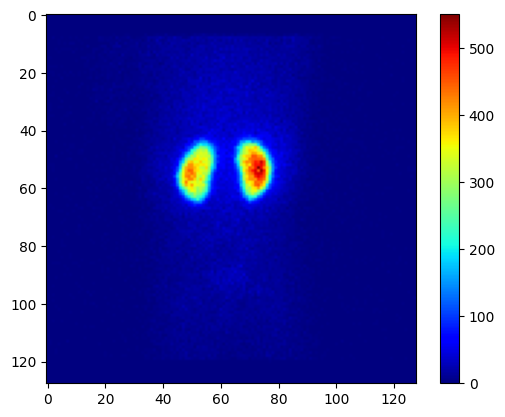

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(arr, cmap='jet')
plt.colorbar()

## Modification de fichiers par lot

On peut aussi utiliser pydicom pour modififier certains tags d'une série de fichiers DICOM.

Une utilisation potentielle de cette fonctionnalité est l'**anonymisation** de fichiers.

Les fichiers présents dans le répertoire `data2/patient2` sont déjà anonymisés mais on va à nouveau modifier l'attribut `PatientName` comme on pourrait le faire pour anonymiser ces fichiers.

In [ ]:
import pydicom as dcm
from pathlib import Path

# La syntaxe suivante permet de rechercher une chaîne de caractères précise dans un liste de fichiers
dcm_files = Path('./data/patient2/').rglob('*.dcm')
dcm_files_CT = Path('./data/patient2/').rglob('*CT*.dcm')
dcm_files_PT = Path('./data/patient2/').rglob('*PT*.dcm')

# La fonction len() affiche la longueur d'une liste (donc ici le nombre de fichiers)
print('Nombre de fichiers total dans la série :',len(list(dcm_files)))
print('Nombre de fichiers TDM dans la serie :',len(list(dcm_files_CT)))
print('Nombre de fichiers TEP dans la serie :',len(list(dcm_files_PT)))

Nombre de fichiers total dans la série : 987
Nombre de fichiers TDM dans la serie : 568
Nombre de fichiers TEP dans la serie : 419


In [ ]:
# Liste contenant tous les fichiers DICOM du dossier patient2
dcm_files = Path('./data/patient2/').rglob('*.dcm')

# Création du nouveau répertoire patient2_anonymised s'il n'existe pas (s'il existe, on ne fait rien)
output_dir = Path('./data/patient2_anonymised/')
output_dir.mkdir(exist_ok=True)

# Boucle sur l'ensemble des fichiers DICOM du répertoire patient2
for file_dcm in dcm_files:
    if not 'new' in file_dcm.name:
        # Lecture de l'entête DICOM de chaque fichier
        ds = dcm.dcmread(str(file_dcm))
        #print(ds.PatientName)
        # Les images DICOM de sortie (après anonymisation) auront le même nom
        out_file = file_dcm.name
        # Modification de l'attribut PatientName : Patient2 --> Optionnel DES MN
        ds.PatientName = "DQPRM"
        # Réécriture des nouveaux fichiers DICOM et stockage dans le dossier patient2_anonymised
        dcm.dcmwrite(str(output_dir / out_file), ds)

AttributeError: module 'pydicom' has no attribute 'read_file'

In [ ]:
# On vérifie que l'attribut PatientName a bien été modifié
newdcm_files = Path('./data/patient2_anonymised/').rglob('*.dcm')
# Nom du patient après anonymisation
print("Vérification --> nom du patient après anonymisation :",dcm.read_file(str(list(newdcm_files)[0])).PatientName)

## Exercice

- Retrouvez les dimensions de l'image et sa résolution
- Retrouvez quel était le radiopharmaceutique injecté

-----

In [ ]:
print('Nombre de lignes :', ...)
print('Nombre de colonnes :',  ...)
print('Résolution :', ...)

In [ ]:
print(dataset.RadiopharmaceuticalInformationSequence)
print(dataset.data_element("RadiopharmaceuticalInformationSequence").tag)

In [ ]:
print(dataset[...,...][0][...,...][0][...,...].value)

## Correction

In [ ]:
print('Nombre de lignes :', dataset[0x0028,0x0010].value)
print('Nombre de colonnes :',  dataset[0x0028,0x0011].value)
print('Résolution :', dataset[0x0028,0x0030].value)

In [ ]:
print(dataset.RadiopharmaceuticalInformationSequence)
print(dataset.data_element("RadiopharmaceuticalInformationSequence").tag)

In [ ]:
print(dataset[0x0054,0x0016][0][0x0054,0x0300][0][0x0008,0x0104].value)